# CNN 이진분류 - 고양이, 강아지 데이터
- 로컬 이미지를 로딩해서 학습

In [98]:
import cupy as cp
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import tensorflow as tf
import keras

In [99]:
import random
seed = 42

random.seed(42)
np.random.seed(42)
cp.random.seed(42)
tf.random.set_seed(42)

np.set_printoptions(precision=4,linewidth=200,suppress=True)

#데이터 준비

In [4]:
!gdown https://drive.google.com/uc?id=1dC-Kso5FonYWtbxtJnJ8_dxO_Jlo8weR

Downloading...
From (original): https://drive.google.com/uc?id=1dC-Kso5FonYWtbxtJnJ8_dxO_Jlo8weR
From (redirected): https://drive.google.com/uc?id=1dC-Kso5FonYWtbxtJnJ8_dxO_Jlo8weR&confirm=t&uuid=bdbfc804-69f3-42da-a6ef-1054a37c7a64
To: /content/cats_and_dogs.zip
100% 68.6M/68.6M [00:00<00:00, 70.8MB/s]


In [5]:
!unzip cats_and_dogs.zip

Archive:  cats_and_dogs.zip
   creating: cats_and_dogs/
   creating: cats_and_dogs/test/
   creating: cats_and_dogs/test/cats/
  inflating: cats_and_dogs/test/cats/cat.2300.jpg  
  inflating: cats_and_dogs/test/cats/cat.2301.jpg  
  inflating: cats_and_dogs/test/cats/cat.2302.jpg  
  inflating: cats_and_dogs/test/cats/cat.2303.jpg  
  inflating: cats_and_dogs/test/cats/cat.2304.jpg  
  inflating: cats_and_dogs/test/cats/cat.2305.jpg  
  inflating: cats_and_dogs/test/cats/cat.2306.jpg  
  inflating: cats_and_dogs/test/cats/cat.2307.jpg  
  inflating: cats_and_dogs/test/cats/cat.2308.jpg  
  inflating: cats_and_dogs/test/cats/cat.2309.jpg  
  inflating: cats_and_dogs/test/cats/cat.2310.jpg  
  inflating: cats_and_dogs/test/cats/cat.2311.jpg  
  inflating: cats_and_dogs/test/cats/cat.2312.jpg  
  inflating: cats_and_dogs/test/cats/cat.2313.jpg  
  inflating: cats_and_dogs/test/cats/cat.2314.jpg  
  inflating: cats_and_dogs/test/cats/cat.2315.jpg  
  inflating: cats_and_dogs/test/cats/cat.

#데이터 로드

In [100]:
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32
DATA_DIR = "/content/cats_and_dogs"

In [101]:
train_ds = keras.utils.image_dataset_from_directory(
    directory=DATA_DIR + "/train", labels = 'inferred', label_mode ='int',
    image_size = (IMG_HEIGHT, IMG_WIDTH), batch_size = BATCH_SIZE,
    shuffle = True, seed = seed
)

Found 2600 files belonging to 2 classes.


In [102]:
class_name = train_ds.class_names
print(class_name)

['cats', 'dogs']


In [103]:
val_ds = keras.utils.image_dataset_from_directory(
    directory=DATA_DIR + "/test", labels = 'inferred', label_mode ='int',
    image_size = (IMG_HEIGHT, IMG_WIDTH), batch_size = BATCH_SIZE,
    shuffle = True, seed = seed
)

Found 400 files belonging to 2 classes.


#EDA

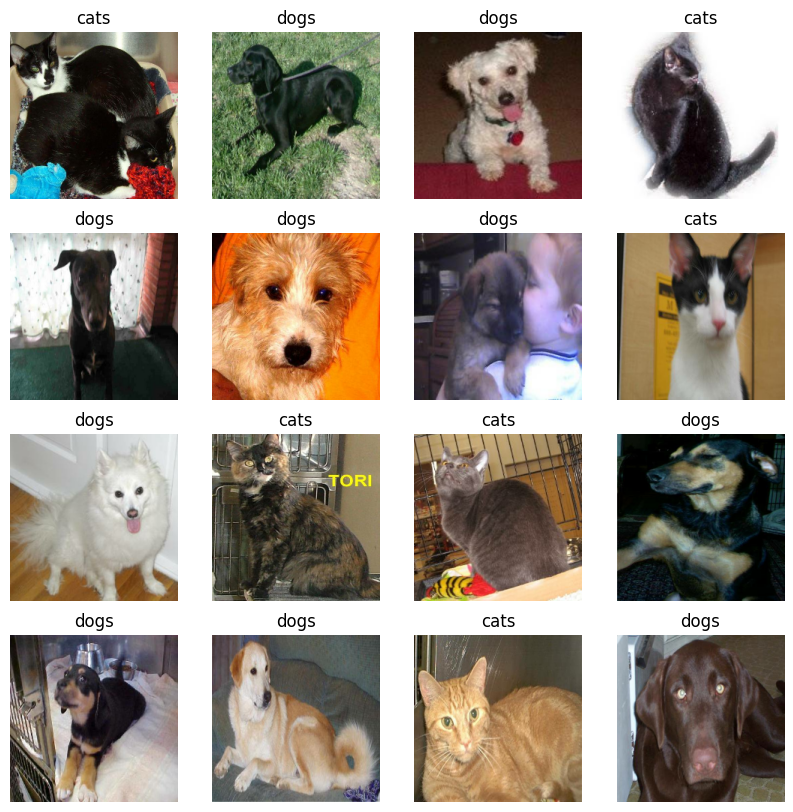

In [43]:
for images, labels in train_ds.take(1):
  break

plt.figure(figsize=(10,10))

for i in range(16):
  ax = plt.subplot(4,4,i+1)
  plt.imshow(images[i].numpy().astype(np.uint8))
  plt.axis("off")
  labels_index = labels[i].numpy()
  plt.title(class_name[labels_index])

plt.show()

#데이터 전처리

### 스케일링(정규화)

In [104]:
# normalization_layer는 전역으로 정의하되, preprocess_image에서는 사용하지 않습니다.
normalization_layer = keras.layers.Rescaling(1/255.)

def preprocess_image(x, y):
  # 이미지만 리사이징합니다.
  x = tf.image.resize(x, [IMG_HEIGHT, IMG_WIDTH])
  return x, y

In [105]:
# train_ds와 val_ds에는 리사이징만 적용합니다.
train_ds = train_ds.map(preprocess_image)
val_ds = val_ds.map(preprocess_image)

### 데이터 로더 최적화

In [106]:
train_ds = train_ds.cache().prefetch(buffer_size = tf.data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size = tf.data.AUTOTUNE)

모델

In [126]:
base = keras.applications.VGG16(
    input_shape = (IMG_HEIGHT, IMG_WIDTH, 3),
    weights = "imagenet", include_top = False,
)

base.trainable = False

In [127]:
base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [128]:
from keras import layers

def build_model():
  # VGG16 모델의 특정 레이어를 동결 (예: 초기 블록들)
  for layer in base.layers:
    if 'block1' in layer.name or 'block2' in layer.name or 'block3' in layer.name:
      layer.trainable = False
    else:
      layer.trainable = True

  model = keras.Sequential([
      # 전처리 및 데이터 증강 레이어를 모델의 첫 부분에 추가합니다.
      normalization_layer, # 모델 내부에서 정규화 적용
      data_augmentaion,    # 모델 내부에서 데이터 증강 적용 (훈련 시에만 활성화)
      base,
      layers.Flatten(),
      layers.Dense(32, activation = 'relu'),
      layers.Dropout(0.5),
      layers.Dense(2, activation = 'softmax')
  ])

  return model

In [129]:
model = build_model() # data_augmentaion 변경 후 모델을 다시 빌드

model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_5 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_6 (Sequential)       │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 12,979,200 (49.51 MB)

 Non-trainable params: 1,735,488 (6.62 MB)

## 컴파일

In [130]:
model.compile(
    optimizer = keras.optimizers.Adam(learning_rate=1e-5), # 미세 조정을 위해 Adam 옵티마이저의 학습률을 낮춥니다.
    loss = 'sparse_categorical_crossentropy',
    metrics = ['accuracy']
)

#학습

In [131]:
EPOCH = 3

history = model.fit(train_ds,validation_data = val_ds, epochs = EPOCH )

Epoch 1/3
82/82 ━━━━━━━━━━━━━━━━━━━━ 10s 49ms/step - accuracy: 0.5848 - loss: 0.6879 - val_accuracy: 0.8300 - val_loss: 0.4239
Epoch 2/3
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.7600 - loss: 0.4857 - val_accuracy: 0.9150 - val_loss: 0.2345
Epoch 3/3
82/82 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.8618 - loss: 0.3330 - val_accuracy: 0.9325 - val_loss: 0.1784


#학습곡선

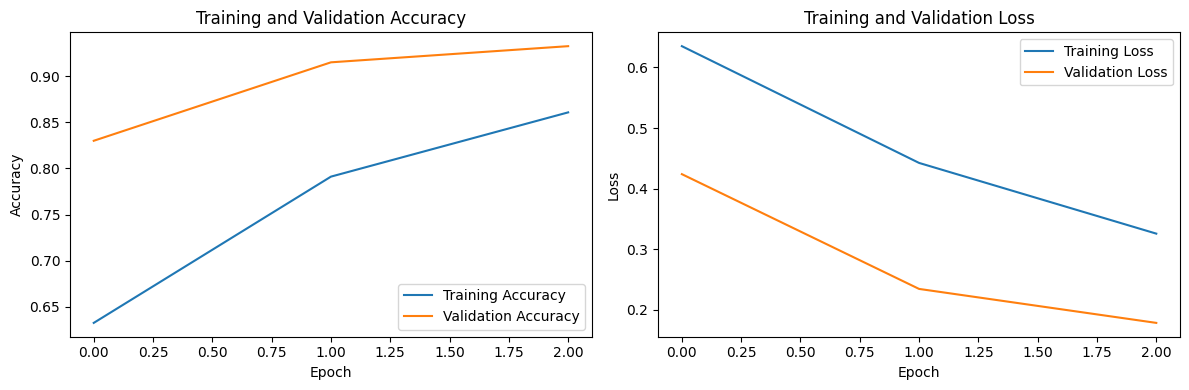

In [133]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

#테스트

In [53]:
# /content/cats_and_dogs/test/cats/cat.2341.jpg
import PIL

image = PIL.Image.open("/content/cats_and_dogs/test/cats/cat.2341.jpg")
image = np.array(image)

In [54]:
image.shape

(417, 299, 3)

In [57]:
x_test = np.expand_dims(image, axis = 0)
x_test.shape

(1, 417, 299, 3)

In [58]:
y_test = np.array([[0]])
y_test.shape

(1, 1)

In [61]:
t2st_ds = tf.data.Dataset.from_tensor_slices((x_test,y_test))

In [65]:
t2st_ds = t2st_ds.map(preprocess_image) # preprocess_image 적용 후 t2st_ds 업데이트
t2st__ = t2st_ds.batch(1)

In [134]:
y_pred = model.predict(t2st__)
y_pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 423ms/step


array([[0.8116, 0.1884]], dtype=float32)

In [135]:
np.argmax(y_pred, axis = 1)

array([0])

In [136]:
np.argmax(y_test, axis = 1) # t2st__ 대신 y_test 사용

array([0])

#데이터 증강

In [121]:
data_augmentaion = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomCrop(IMG_HEIGHT, IMG_WIDTH, seed=seed),
    # layers.RandomGrayscale(seed=seed) # 이 레이어를 제거하여 순환 오류를 방지합니다.
])

(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

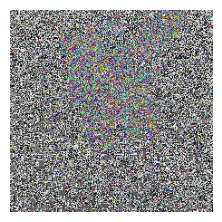

In [137]:
for images, labels in train_ds.take(1):
    single_image = images[1]
    single_image_batch = tf.expand_dims(single_image, axis=0)
    break

plt.figure(figsize=(12, 12))
ax = plt.subplot(3, 4, 1)
# plt.imshow(single_image.numpy().astype(np.uint8))
plt.imshow((single_image.numpy() * 255.).astype(np.uint8))
plt.axis('off')

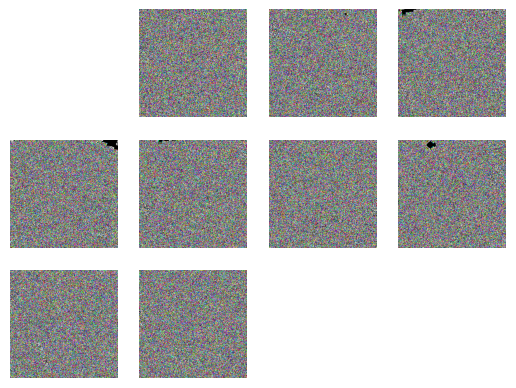

In [123]:
for i in range(9):
  ax = plt.subplot(3, 4, i + 2)
  aug_image = data_augmentaion(single_image_batch, training=True)
  plt.imshow((aug_image[0].numpy() * 255).astype(np.uint8))
  plt.axis('off')
plt.show()

## 학습용 데이터 적용

In [124]:
def apply_rescaling(image, label):
  return normalization_layer(image), label

def apply_augmentation(image, label):
  return data_augmentaion(image, training=True), label

In [125]:
train_ds = train_ds.cache().shuffle(buffer_size = 1000)
# 이제 정규화와 증강은 모델 내부에서 처리되므로, 여기서 map 호출은 제거합니다.
# train_ds = train_ds.map(apply_rescaling, num_parallel_calls = tf.data.AUTOTUNE)
# train_ds = train_ds.map(apply_augmentation, num_parallel_calls = tf.data.AUTOTUNE)